In [1]:
%load_ext autoreload
%autoreload 2


import matplotlib.pyplot as plt
import matplotlib
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm
from matplotlib.colors import LogNorm
import numpy as np
import darling


In [2]:
plt.style.use("seaborn-v0_8-white")
fontsize = 16  # General font size for all text
ticksize = 16  # tick size
plt.rcParams["font.size"] = fontsize
plt.rcParams["xtick.labelsize"] = ticksize
plt.rcParams["ytick.labelsize"] = ticksize

In [5]:
mosa = np.load("/dtu/3d-imaging-center/projects/2022_QIM_PMP/analysis/Adam/CDD/Mosa/mosa_scans/mosa_00015.npy")

voxel_size = 0.0664 

aspect = 1/np.tan(np.deg2rad(15.06)*2)

In [6]:
from scipy.ndimage import gaussian_filter, zoom


In [7]:
mu_min_data  = -0.0004
mu_max_data  =  0.0004
chi_min_data = -0.0013
chi_max_data =  0.0013

buffer = 1e-4  # small extra margin in radians

mu_min  = mu_min_data  - buffer
mu_max  = mu_max_data  + buffer
chi_min = chi_min_data - buffer
chi_max = chi_max_data + buffer

# keep the same number of steps as before
n_mu  = 40   # was: len(mu_steps)
n_chi = 6   # was: len(chi_steps)

_mu_steps  = np.linspace(mu_min,  mu_max,  n_mu)
_chi_steps = np.linspace(chi_min, chi_max, n_chi)
_mu_grid, _chi_grid = np.meshgrid(_mu_steps, _chi_steps, indexing="ij")

# motors_array with shape (2, n_mu, n_chi)
motors_array = np.stack([_mu_grid, _chi_grid], axis=0)


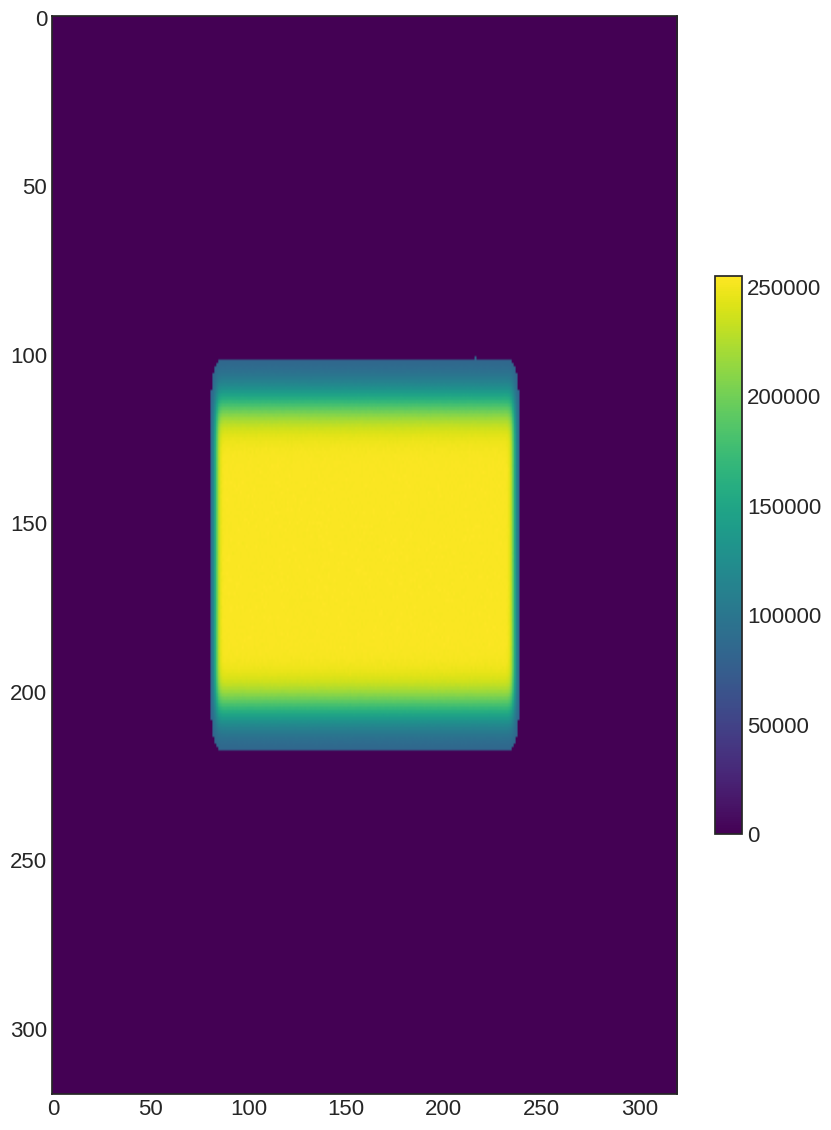

In [8]:
plt.figure(figsize=(12, 14))
plt.imshow(np.sum(mosa, axis=(-1, -2)), cmap="viridis", aspect=aspect)
plt.colorbar(fraction=0.03, pad=0.04)
plt.show()

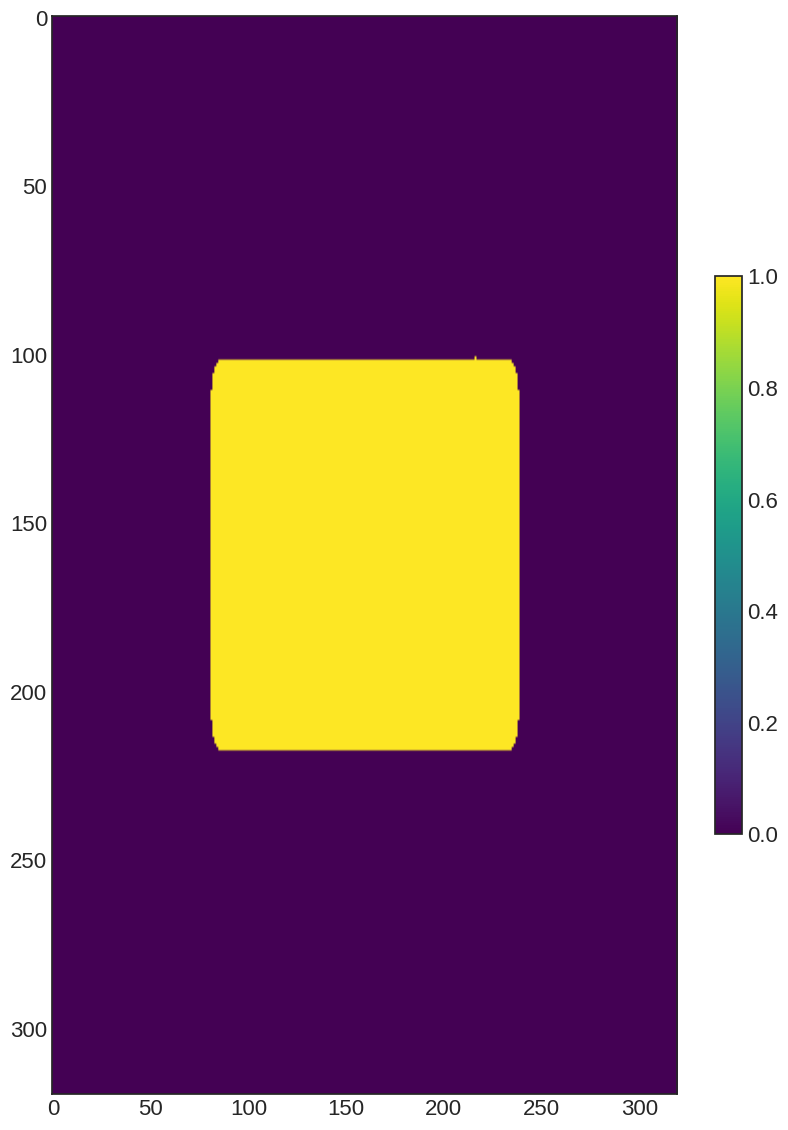

(320, 320)


In [9]:
#make a mask based on np.sum(mosa, axis=(-1, -2))
mask = np.sum(mosa, axis=(-1, -2)) > 40000
plt.figure(figsize=(12, 14))
plt.imshow(mask, cmap="viridis", aspect=aspect)
plt.colorbar(fraction=0.03, pad=0.04)
plt.show()

print(mask.shape)

#apply the mask to the mosa
masked_mosa = mosa.copy()
masked_mosa[~mask] = 0


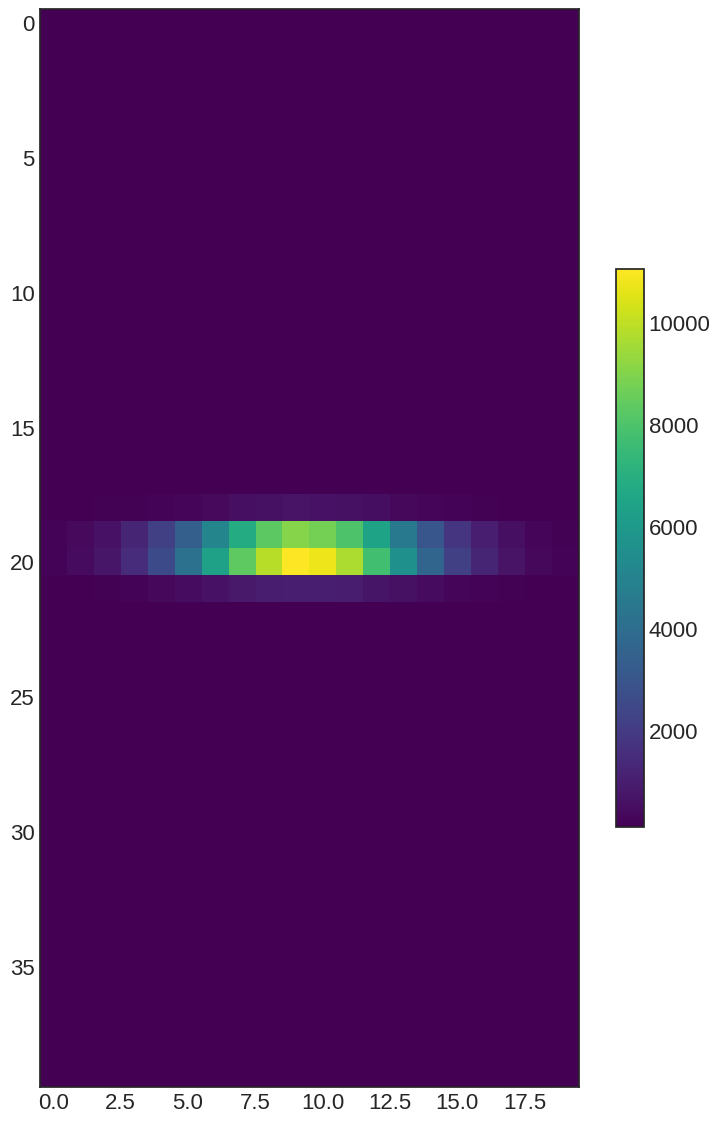

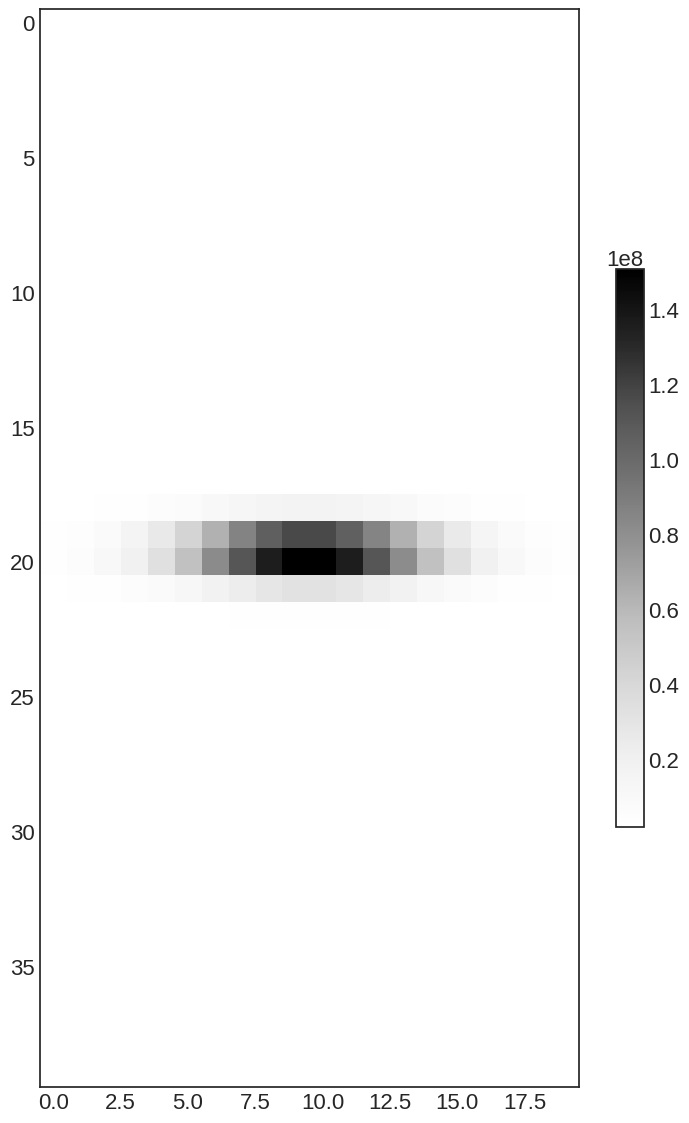

In [10]:
plt.figure(figsize=(12, 14))
plt.imshow(masked_mosa[125, 150, :, :], cmap="viridis")
plt.colorbar(fraction=0.03, pad=0.04)
plt.show()


plt.figure(figsize=(12, 14))
plt.imshow(np.sum(masked_mosa, axis=(0,1)))
plt.colorbar(fraction=0.03, pad=0.04)
plt.show()


In [11]:
mosa.shape

(320, 320, 40, 20)

In [12]:
#take the median of first 2 and last 2 frames as background
background = np.median(mosa[:, :, 38:-38, -2:], axis=(-2, -1))


/dtu/3d-imaging-center/projects/2022_QIM_PMP/analysis/Adam/miniconda3/envs/imaging_latest/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/dtu/3d-imaging-center/projects/2022_QIM_PMP/analysis/Adam/miniconda3/envs/imaging_latest/lib/python3.12/site-packages/numpy/_core/_methods.py:139: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


In [13]:
mu_steps = np.linspace(-0.0005, 0.0005, n_mu)
chi_steps = np.linspace(-0.0015, 0.0015, n_chi)

In [ ]:
darling.

Object `darling.reader` not found.


In [ ]:
reader = darling.reader.MosaScan("nowhere")

dset = darling.DataSet(reader)

dset.data = masked_mosa.astype(np.uint16)

# the motors are a an array of [2,20,20] defined by the steps in rocking and rolling
dset.motors = np.array([np.tile(mu_steps[:, np.newaxis], (1, len(chi_steps))), np.tile(chi_steps[np.newaxis, :], (len(mu_steps), 1))])

dset.motors.shape


AttributeError: module 'darling' has no attribute 'Reader'

In [24]:

dset.subtract(median_bck[..., None, None].astype(np.uint16))

In [25]:
dset.motors = motors_array

In [26]:
features = darling.properties.gaussian_mixture(dset.data, k=4, coordinates=dset.motors)

In [27]:
mu, cov = darling.properties.moments(dset.data, coordinates=dset.motors)

mu[~mask] = np.nan

In [28]:
first_maxima_mean = np.concatenate(
   (features["mean_motor1"][..., 0, None], features["mean_motor2"][..., 0, None]),
   axis=-1,
)

first_maxima_mean[~mask] = np.nan
rgbmap1, colorkey, colorgrid = darling.properties.rgb(
   first_maxima_mean, norm="dynamic", coordinates=dset.motors
)

second_maxima_mean = np.concatenate(
   (features["mean_motor1"][..., 1, None], features["mean_motor2"][..., 1, None]),
   axis=-1,
)

second_maxima_mean[~mask] = np.nan
rgbmap2, colorkey2, colorgrid2 = darling.properties.rgb(
   second_maxima_mean, norm="full", coordinates=dset.motors
)



In [29]:
import scipy.ndimage
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.ticker import FuncFormatter
from matplotlib.ticker import FixedLocator
import matplotlib.patheffects as pe

def get_roi( diffmax, threshold, pad_row=20, pad_col=20, filter_size=5):
    mask = diffmax > threshold
    mask = scipy.ndimage.median_filter(mask.astype(float), filter_size)
    mask = scipy.ndimage.binary_dilation(mask.astype(float), np.ones((3,3)), iterations=filter_size)
    r, c = np.where(mask)
    r1, r2, c1, c2 = (r.min()-pad_row, r.max()+pad_row+1, c.min()-pad_col, c.max()+pad_col+1)
    return r1, r2, c1, c2, mask


def add_color_encoding_legend(
    ax,
    colorgrid,
    colorkey,
    *,
    xlabel=r"$\mathbf{\chi}$",       # Bold Greek Chi
    ylabel=r"$\mathbf{\mu}$",        # Bold Greek Mu
    size_inches=2.0,                 # Absolute size in inches (Square Box)
    loc=2,
    dx=0.02,
    dy=0.02,
    fontsize=20,
    scale=1e4,
    scale_text=r"$\mathbf{\times 10^{-4}\,rad}$", # Bold math text
    nticks=3,
):
    # 1. Anchor Logic
    anchors = {1: (1, 1), 2: (0, 1), 3: (0, 0), 4: (1, 0)}
    x0, y0 = anchors[loc]
    
    if loc == 1: dx_ = -dx; dy_ = -dy
    elif loc == 2: dx_ = dx;  dy_ = -dy
    elif loc == 3: dx_ = dx;  dy_ = dy
    elif loc == 4: dx_ = -dx; dy_ = dy

    # 2. Create Inset (Physical Square)
    # width=size_inches, height=size_inches guarantees the box is square
    # regardless of the parent image's aspect ratio.
    ax_inset = inset_axes(
        ax,
        width=size_inches,   
        height=size_inches, 
        loc=loc,
        bbox_to_anchor=(x0 + dx_, y0 + dy_),
        bbox_transform=ax.transAxes,
        borderpad=0,
    )

    # 3. Plot Data
    # shading='auto' handles the grid. 
    # We rely on default aspect='auto' so it STRETCHES to fill the square box.
    ax_inset.pcolormesh(*colorgrid, colorkey, shading="auto")
    
    # 4. Remove Margins
    # This ensures the color touches the axis spines exactly.
    ax_inset.margins(0)

    # 5. Styling
    for spine in ax_inset.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.0)
        spine.set_color("black")

    # Ticks formatting
    def _fmt(v, pos):
        val = v * scale
        if abs(val) < 1e-9: val = 0
        return f"{val:.1f}"
    
    tickfmt = FuncFormatter(_fmt)
    ax_inset.xaxis.set_major_formatter(tickfmt)
    ax_inset.yaxis.set_major_formatter(tickfmt)
    vals_x = colorgrid[0] * scale
    vals_y = colorgrid[1] * scale
    vmin_x, vmax_x = vals_x.min(), vals_x.max()
    vmin_y, vmax_y = vals_y.min(), vals_y.max()

    step = 0.5

    # Create a list of ticks spanning from vmin to vmax in 0.5 steps
    tick_list_x = np.arange(
        np.floor(vmin_x / step) * step,
        np.ceil(vmax_x / step) * step + step/2,
        step
    )

    tick_list_y = np.arange(
        np.floor(vmin_y / step) * step,
        np.ceil(vmax_y / step) * step + step/2,
        step
    )

    # Extract first and last tick
    xticks = [tick_list_x[1], tick_list_x[-2]]
    yticks = [tick_list_y[1], tick_list_y[-2]]


    xticks_locs = np.array(xticks) / scale
    yticks_locs = np.array(yticks) / scale

    ax_inset.xaxis.set_major_locator(FixedLocator(xticks_locs))
    ax_inset.yaxis.set_major_locator(FixedLocator(yticks_locs))

    thick_stroke = [pe.withStroke(linewidth=0.1, foreground="black")]


    # 6. Bold Labels & Title
    # Using \mathbf{} inside LaTeX ensures it uses the bold math font.
    ax_inset.set_xlabel(xlabel, fontsize=fontsize, labelpad=5, path_effects=thick_stroke)
    ax_inset.set_ylabel(ylabel, fontsize=fontsize, labelpad=5, path_effects=thick_stroke)

    ax_inset.xaxis.label.set_path_effects(thick_stroke)
    ax_inset.yaxis.label.set_path_effects(thick_stroke)

    # Bold Tick Labels
    # We iterate through ticks to set their weight
    ax_inset.tick_params(axis='both', labelsize=fontsize-10)
    for t in ax_inset.get_xticklabels() + ax_inset.get_yticklabels():
        t.set_fontweight("bold")

    # Bold Top Label
    ax_inset.text(
        0.5, 1.1, 
        scale_text,
        transform=ax_inset.transAxes,
        ha="center", va="bottom",
        fontsize=fontsize -6,
    )

    return ax_inset

In [30]:
diffmax = dset.data.max(axis=(-1, -2))
r1, r2, c1, c2, roi_mask = get_roi(
    diffmax, threshold=220, pad_row=10, pad_col=10, filter_size=9
)

In [31]:
print(r1, r2, c1, c2)

94 226 64 256


In [32]:
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["figure.dpi"] = 300


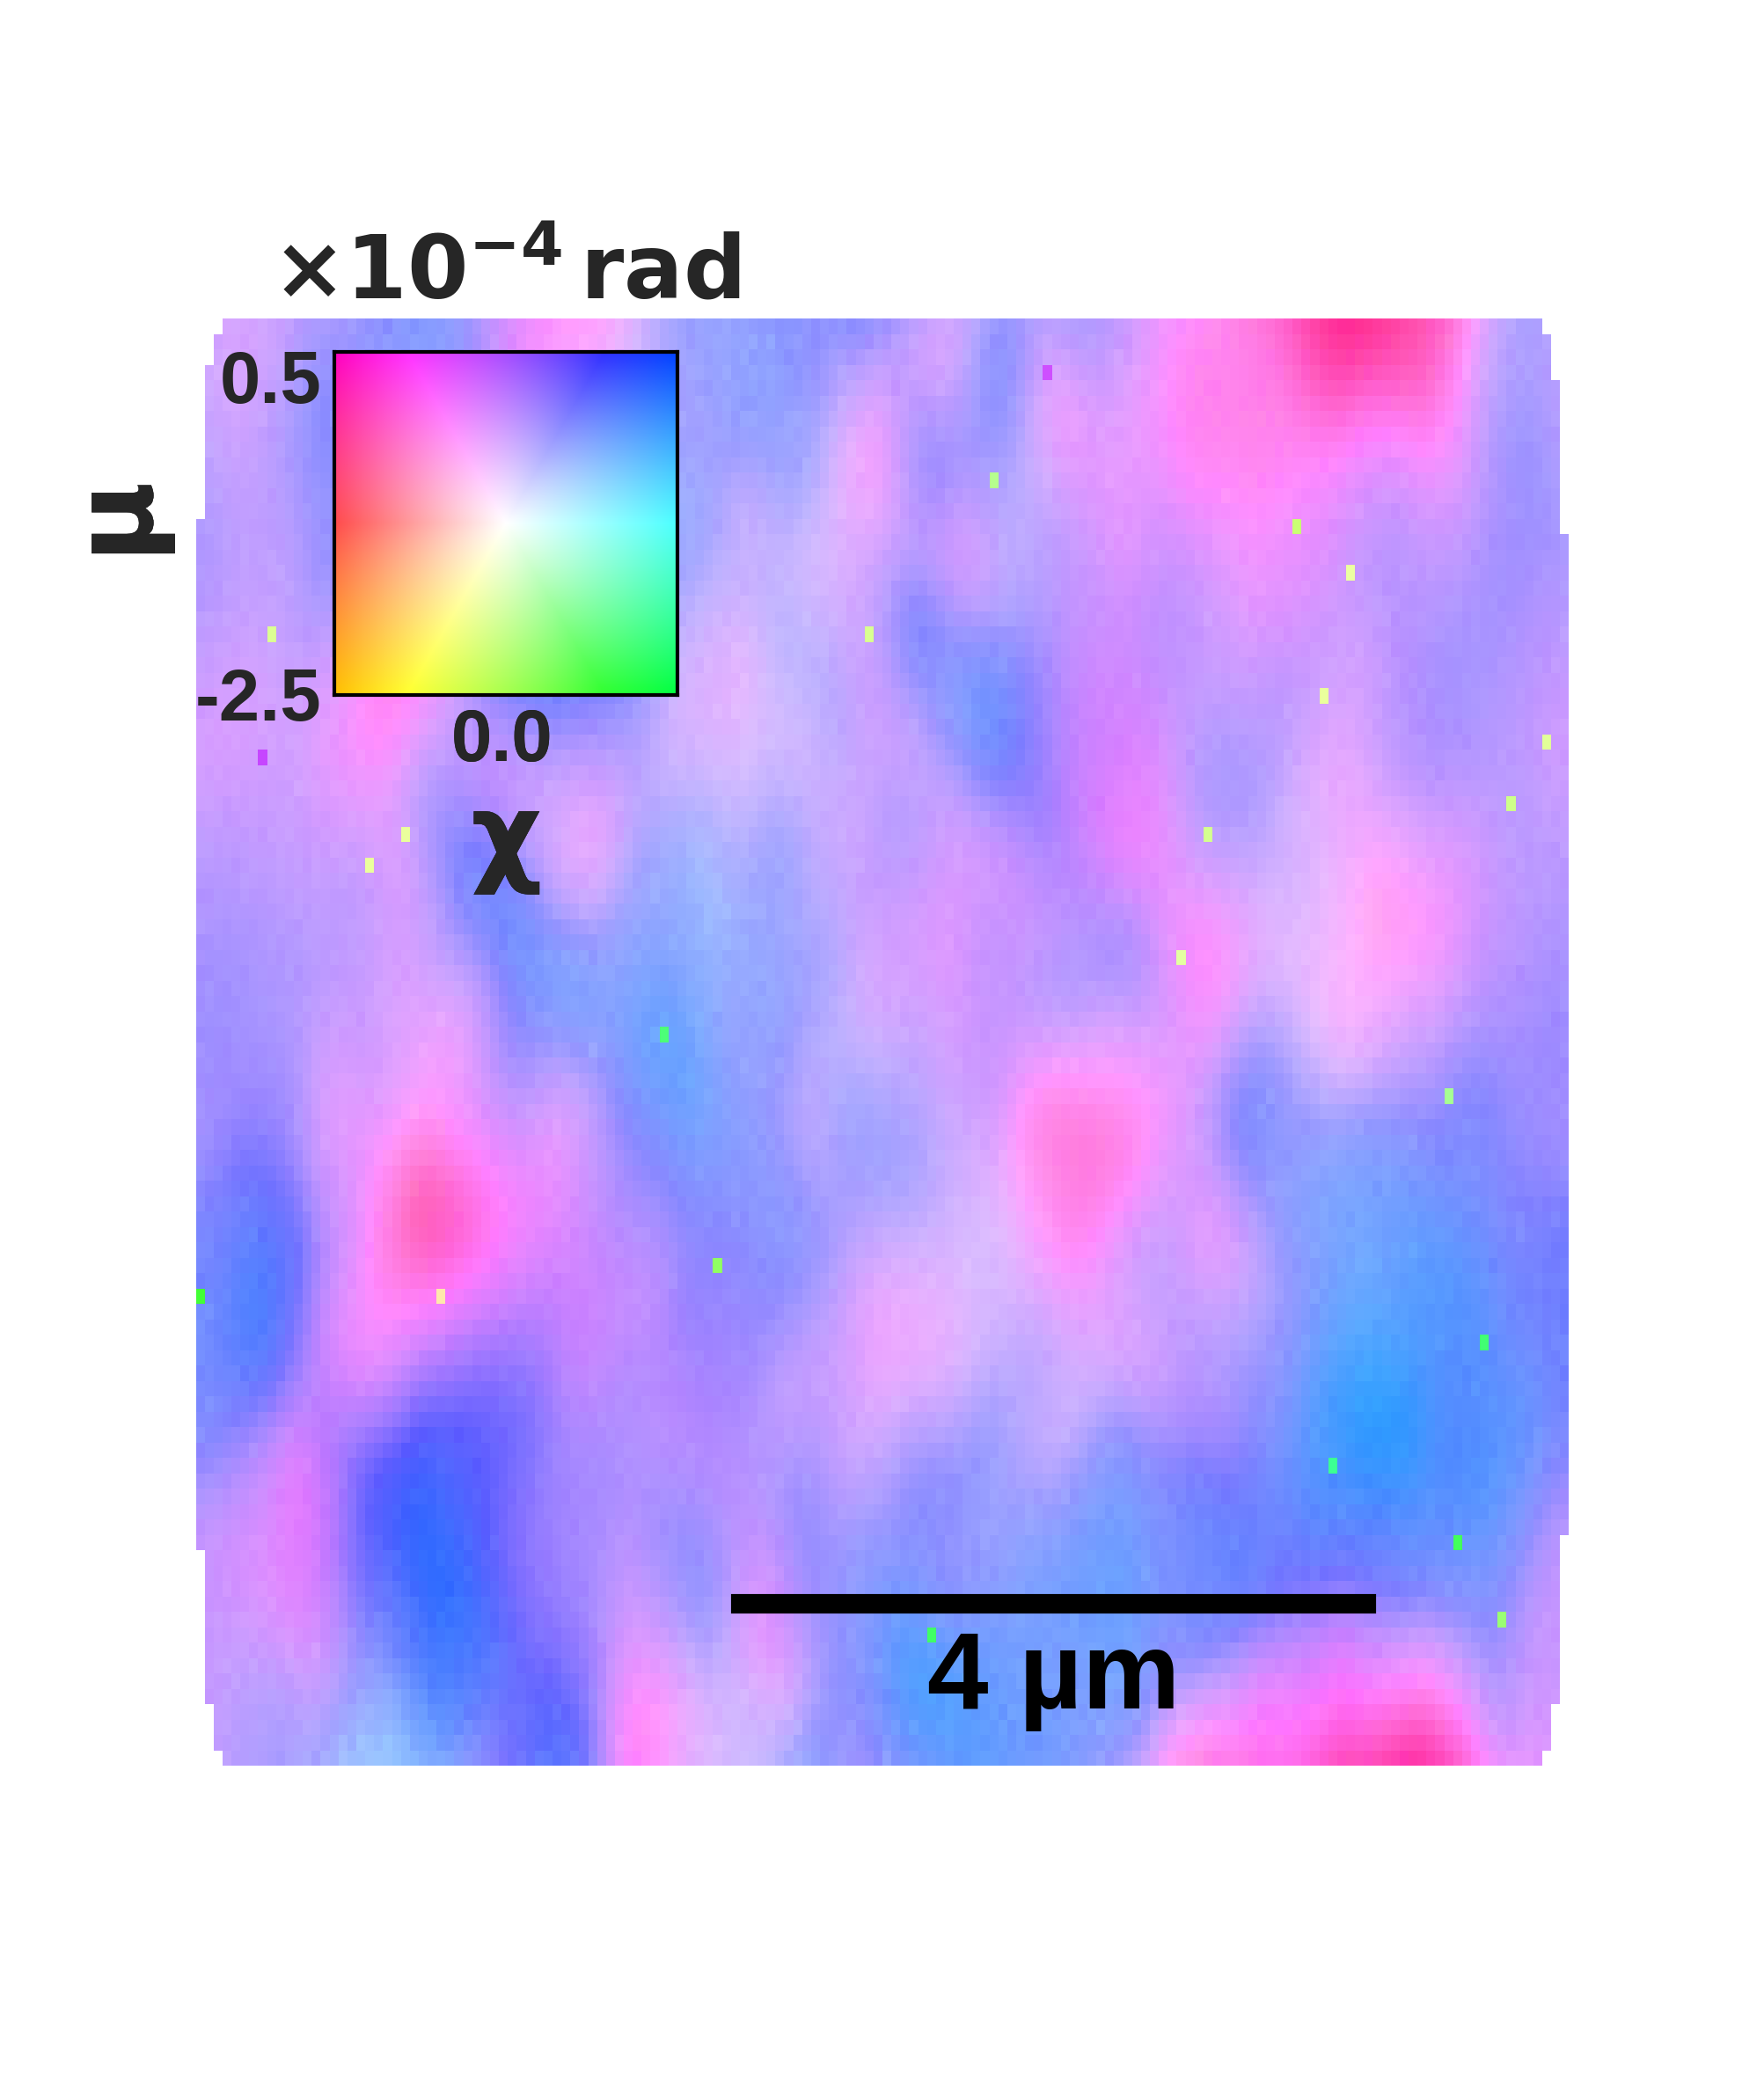

In [ ]:
m1 = dset.motors[0].copy()
m1 -= np.median(dset.motors[0])
m1 = m1 * 1e3

m2 = dset.motors[1].copy()
m2 -= np.median(dset.motors[1])
m2 = m2 * 1e3

# Gaussian mixture features
feats = darling.properties.gaussian_mixture(
    dset.data,
    k=4,
    coordinates=dset.motors,
)

# ---------- 1) RGB map of first component mean (μ, χ) ----------
first_mean = np.concatenate(
    (
        feats["mean_motor1"][..., 0, None],
        feats["mean_motor2"][..., 0, None],
    ),
    axis=-1,
)
first_mean[~mask] = np.nan

rgbmap1, colorkey, colorgrid = darling.properties.rgb(
    first_mean,
    norm="dynamic",
    coordinates=dset.motors,
)

rgb_display = rgbmap1.copy()
rgb_display[~mask] = np.nan

fig_rgb, ax_rgb = plt.subplots(1, 1, figsize=(10, 10))
im_rgb = ax_rgb.imshow(rgb_display[r1:r2, c1:c2], aspect=aspect)

add_color_encoding_legend(
    ax_rgb,
    colorgrid,
    colorkey,
    fontsize=30,
    size_inches=1.3,  # <--- Use this instead of width/height
    loc=2,
    dx=0.18,
    dy=0.16,
)
scalebar = AnchoredSizeBar(
        ax_rgb.transData,
        bar_px,                     # length in data units (pixels)
        r"4 µm",                    # label
        loc='lower center',
        bbox_to_anchor=(0.6, 0.15),   # (x,y) in axes coordinates
        bbox_transform=ax_rgb.transAxes,        # placement
        pad=0.1,
        borderpad=0.1,
        sep=5,
        color='black',
        frameon=False,
        size_vertical=1,            # thickness in pixels (visually consistent)
        fontproperties=fontprops,
    )
ax_rgb.add_artist(scalebar)

for spine in ax_rgb.spines.values():
    spine.set_visible(False)
ax_rgb.set_xticks([])
ax_rgb.set_yticks([])
fig_rgb.savefig("/dtu/3d-imaging-center/projects/2022_QIM_PMP/analysis/Adam/CDD/Microstructures/step_10.png", dpi=300, bbox_inches="tight", pad_inches=0)


#from IPython.display import Image
#Image("preview.png")

In [44]:


bar_um = 4.0                        # micrometers
bar_px = bar_um / (pixel_size/11.68)          # ≈ 30.12 px
bar_px = int(round(bar_px)) 

print(pixel_size)
print(bar_px)



bar_height = 6                       # px thickness on screen
bar_color = "white"

fontprops = fm.FontProperties(size=30, weight="bold")




0.65
72


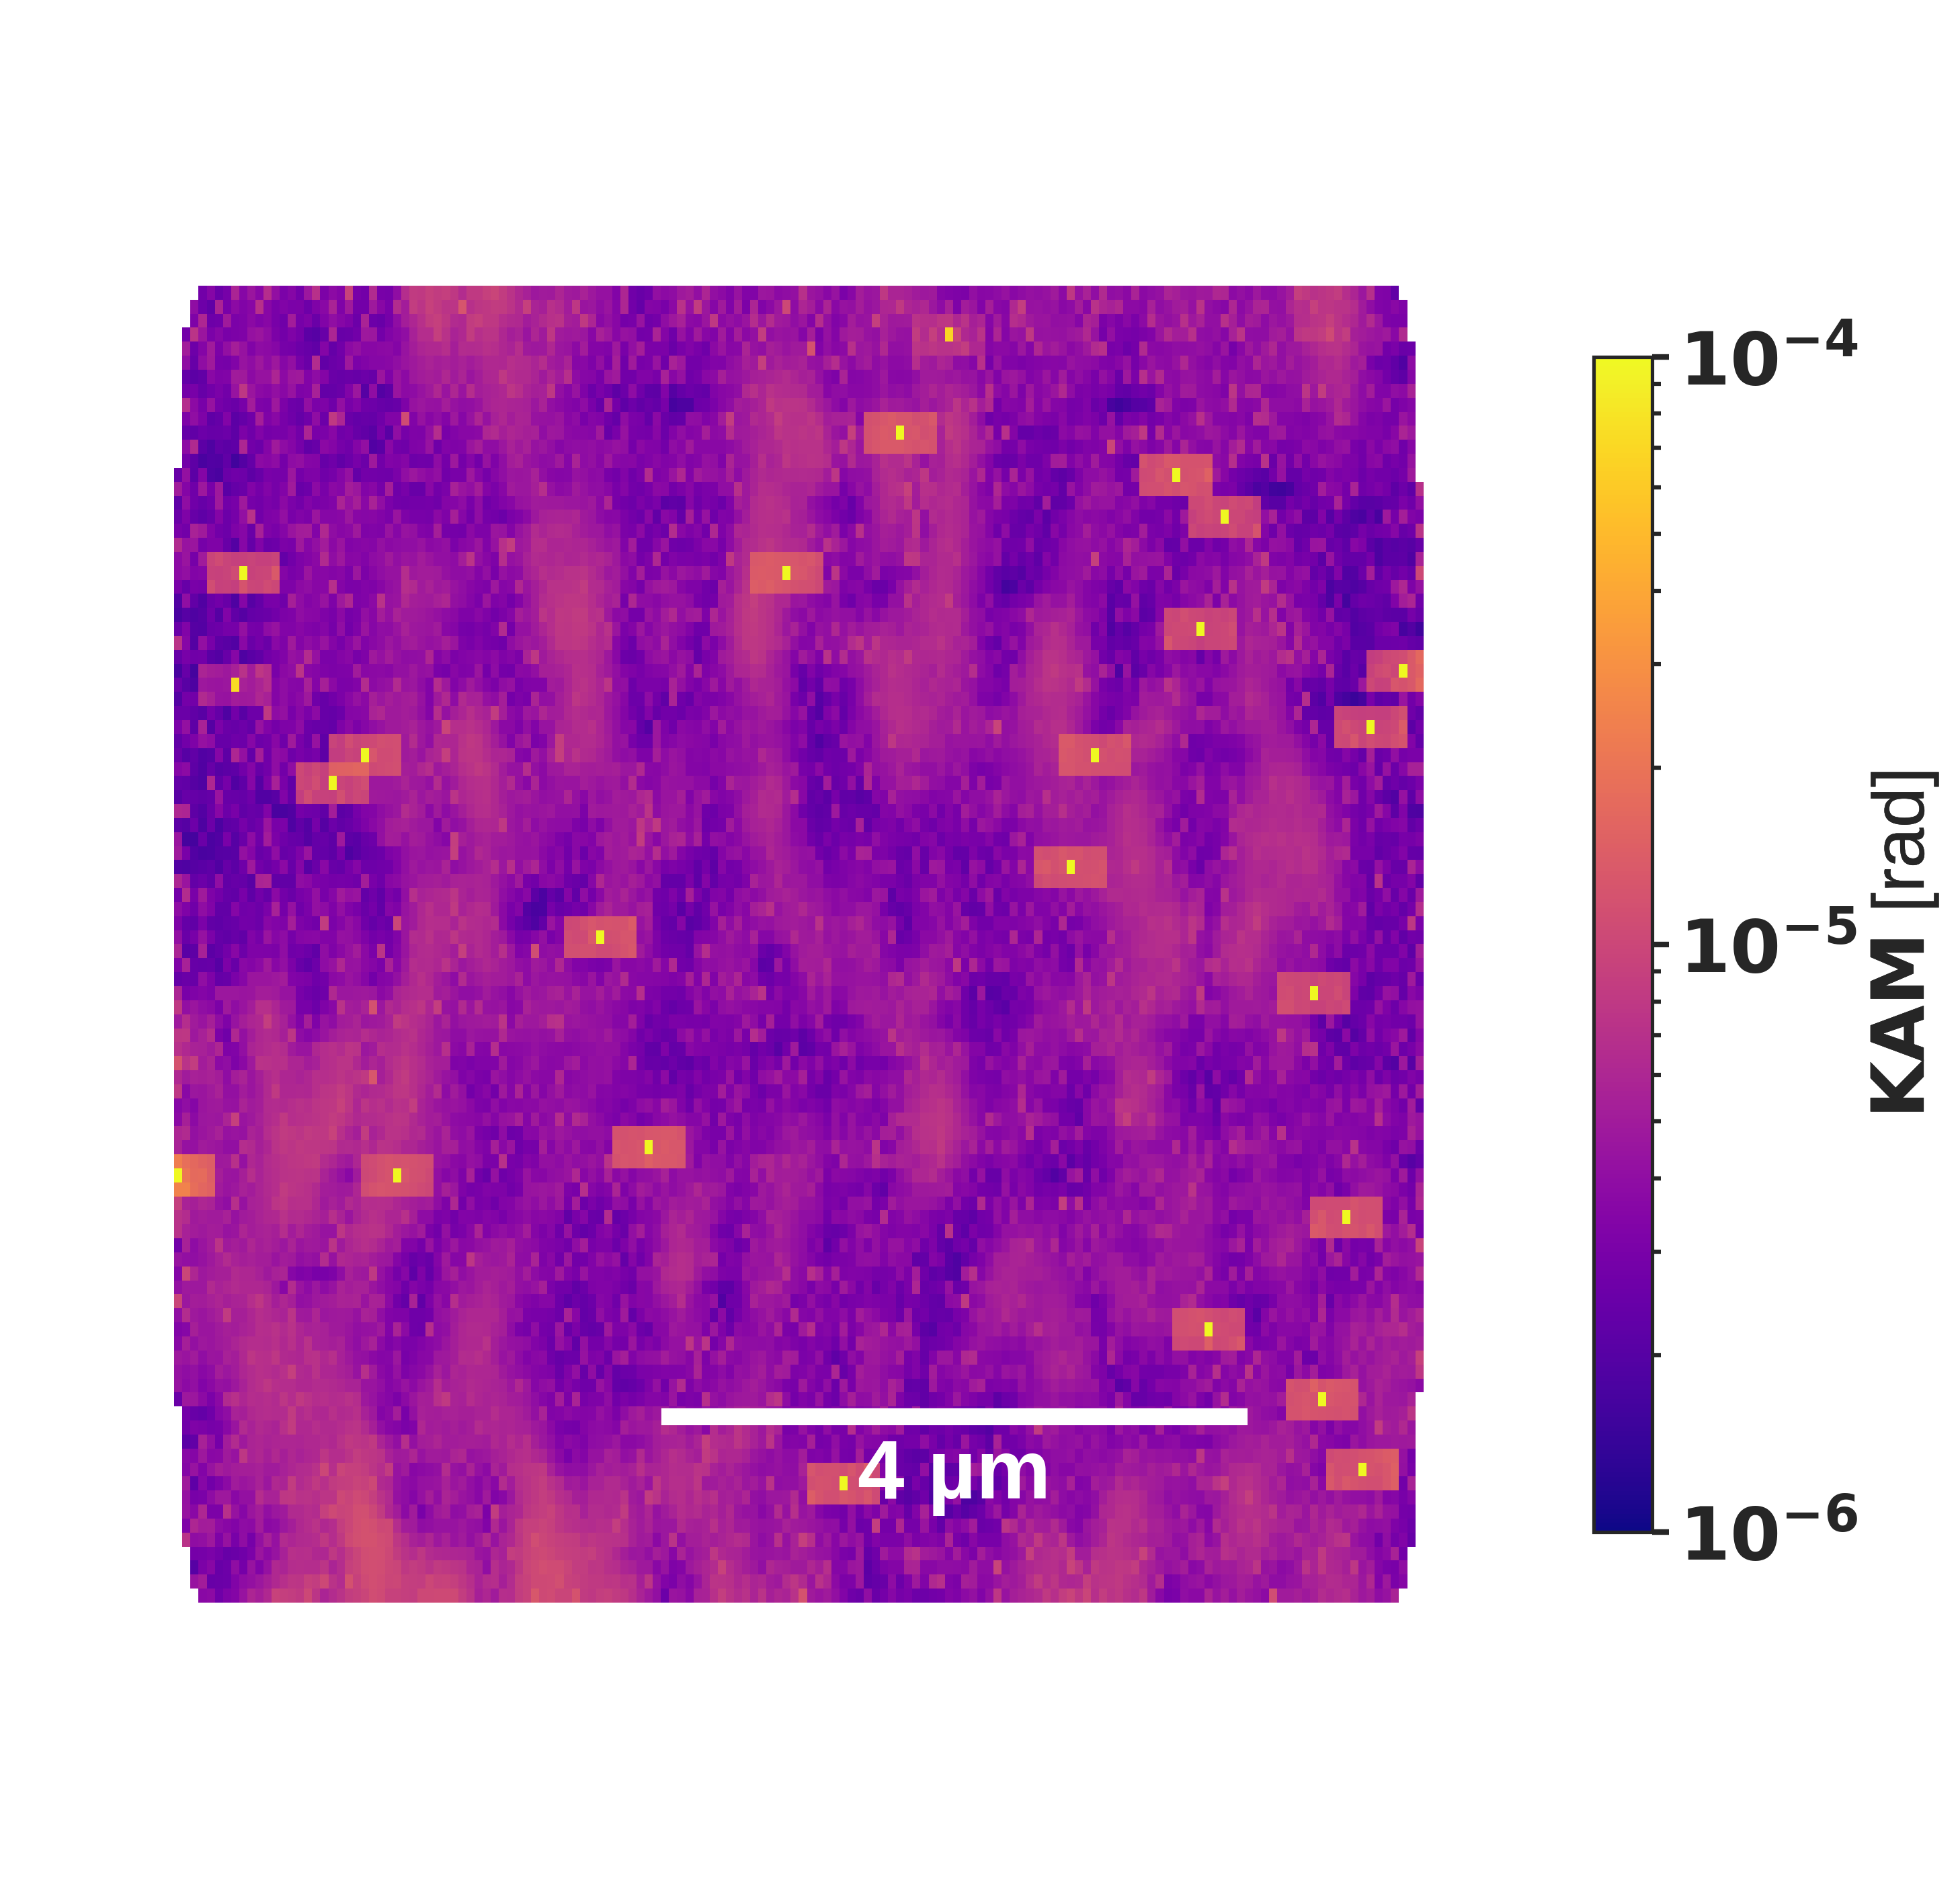

In [45]:
kernel_size = (3, 9)
kam = darling.properties.kam(first_mean, size=kernel_size)

kam_display = kam.copy()
kam_display[~roi_mask] = np.nan

# log scale: only strictly positive values
kam_display = np.where(kam_display <= 0, np.nan, kam_display)

# robust range from percentiles
vmin_kam = np.nanpercentile(kam_display, 1)
vmax_kam = np.nanpercentile(kam_display, 99)
vmin_kam = max(vmin_kam, 1e-6)  # avoid silly tiny vmin

# snap range to powers of 10
emin = int(np.floor(np.log10(vmin_kam)))
emax = int(np.ceil(np.log10(vmax_kam)))

# enforce at least 2 decades
if emax == emin:
    emax = emin + 1

vmin_kam = 10.0**emin
vmax_kam = 10.0**emax

norm_kam = LogNorm(vmin=vmin_kam, vmax=vmax_kam)

fig_kam, ax_kam = plt.subplots(1, 1, figsize=(10, 10))
im_kam = ax_kam.imshow(
    kam_display[r1:r2, c1:c2],
    aspect=aspect,
    cmap="plasma",
    norm=norm_kam,
)

# thick outline for colorbar label (same style as ρ_GND)
thick_stroke = [pe.withStroke(linewidth=0.1, foreground="black")]

cbar_kam = fig_kam.colorbar(im_kam, ax=ax_kam, fraction=0.036, pad=0.01)
cbar_kam.set_label(
    r"$\mathbf{KAM}$ [rad]",
    fontsize=26,
    path_effects=thick_stroke,
)

# pure 10^x ticks, at least 2
exps = np.arange(emin, emax + 1)
if exps.size < 2:
    exps = np.array([emin, emin + 1])

ticks = 10.0**exps
cbar_kam.set_ticks(ticks)
cbar_kam.set_ticklabels([rf"$\mathbf{{10^{{{e}}}}}$" for e in exps])

cbar_kam.ax.tick_params(labelsize=26, which="major", size=6, width=2)
cbar_kam.ax.tick_params(which="minor", size=3, width=1.5)
for t in cbar_kam.ax.get_yticklabels():
    t.set_fontweight("bold")

# scalebar – same style as ρ_GND
scalebar_kam = AnchoredSizeBar(
    ax_kam.transData,
    bar_px,                      # length in data units (pixels)
    r"4 µm",                     # label
    loc="lower center",
    bbox_to_anchor=(0.6, 0.15),
    bbox_transform=ax_kam.transAxes,
    pad=0.4,
    borderpad=0.5,
    sep=5,
    color="white",
    frameon=False,
    size_vertical=1,
    fontproperties=fontprops,
)
ax_kam.add_artist(scalebar_kam)

for spine in ax_kam.spines.values():
    spine.set_visible(False)
ax_kam.set_xticks([])
ax_kam.set_yticks([])

plt.tight_layout()
plt.show()

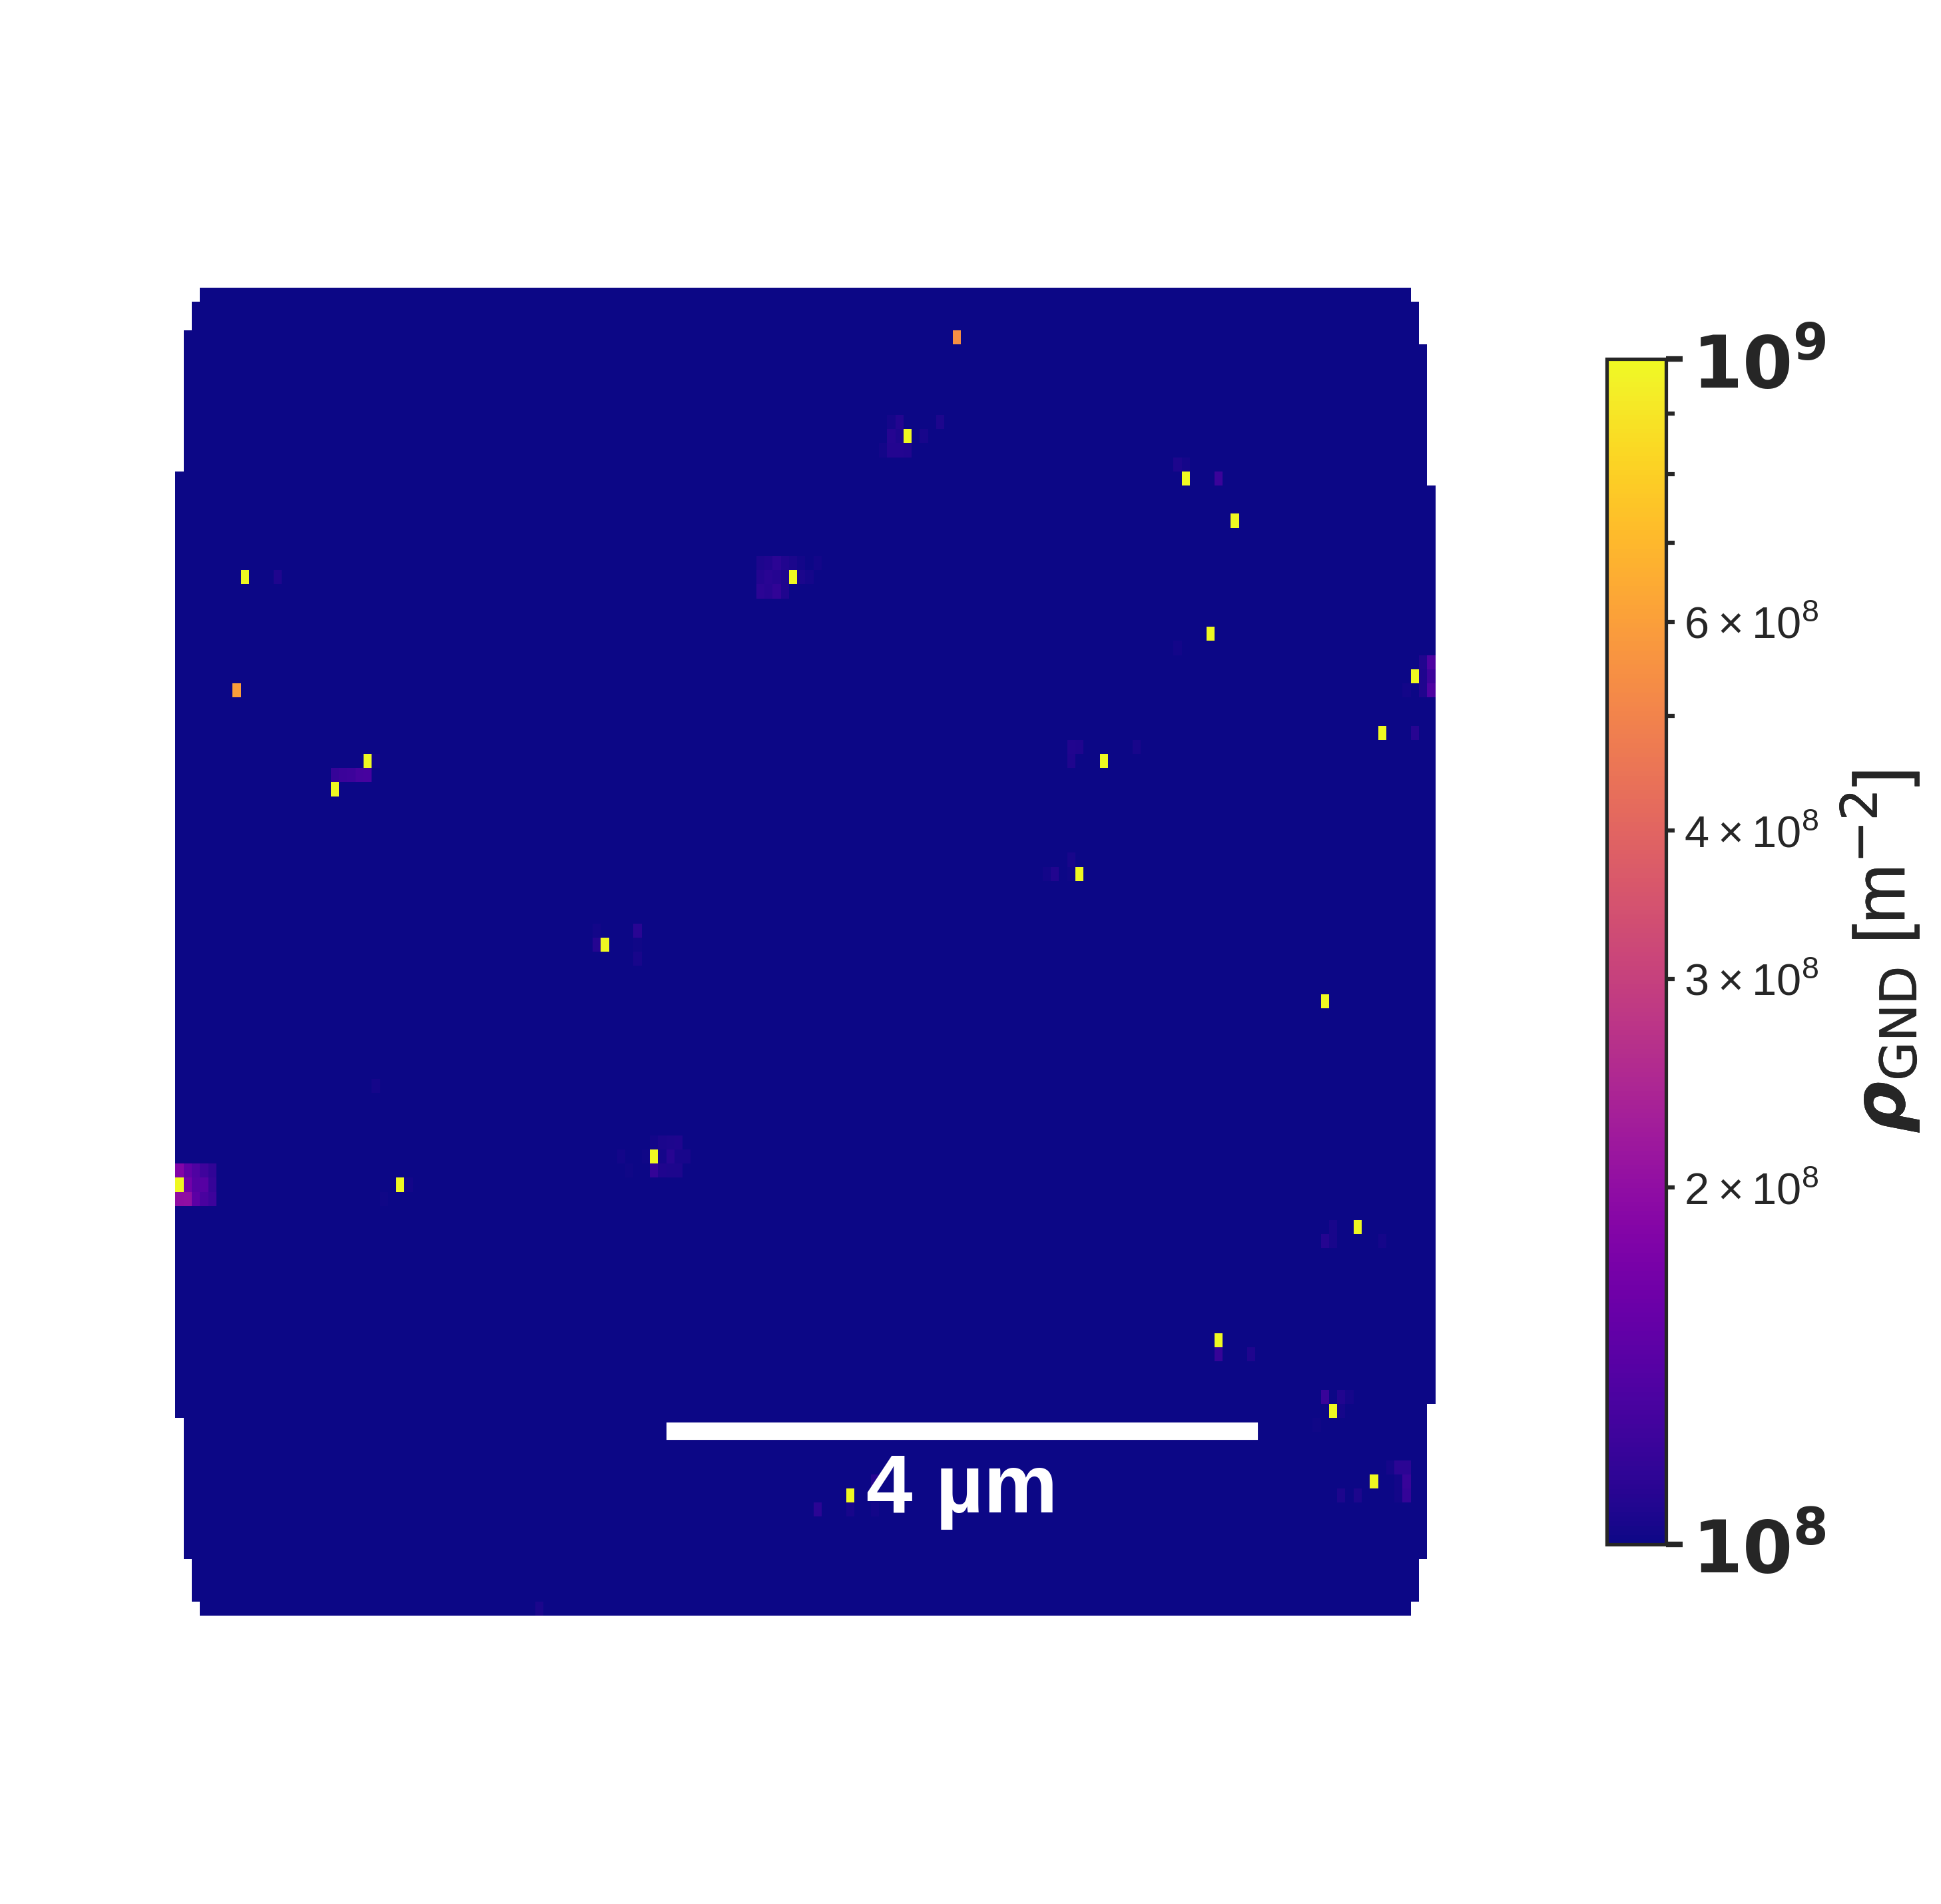

In [46]:
# ---------- ρ_GND from KAM ----------

pixel_size_sample_m = (pixel_size / magnification) * 1e-6  # m
L = kernel_size[1] * pixel_size_sample_m

# Ni Burgers vector from lattice parameter 3.52 Å (<110>)
a_ang = 3.52  # Angstrom
a_m = a_ang * 1e-10
average_burgers_length = a_m / np.sqrt(2.0)

# KAM is in mrad -> convert to rad
kam_rad = kam / 1000.0

dislocation_density = kam_rad / (average_burgers_length * L)

rho_display = dislocation_density.copy()
rho_display[~roi_mask] = np.nan  # same ROI mask as KAM
rho_display = np.where(rho_display <= 0, np.nan, rho_display)

# crop to the same ROI window as KAM
rho_roi = rho_display[r1:r2, c1:c2]

# --- log scale, same style/forcing as KAM ---

# robust range from percentiles
vmin_rho = np.nanpercentile(rho_roi, 1)
vmax_rho = np.nanpercentile(rho_roi, 99)
vmin_rho = max(vmin_rho, 1e8)  # physical floor if you prefer

# snap to powers of 10
emin_rho = int(np.floor(np.log10(vmin_rho)))
emax_rho = int(np.ceil(np.log10(vmax_rho)))

# enforce at least 2 decades
if emax_rho == emin_rho:
    emax_rho = emin_rho + 1

vmin_rho = 10.0**emin_rho
vmax_rho = 10.0**emax_rho

norm_rho = LogNorm(vmin=vmin_rho, vmax=vmax_rho)

fig_rho, ax_rho = plt.subplots(1, 1, figsize=(10, 10))
im_rho = ax_rho.imshow(
    rho_roi,
    aspect=aspect,
    cmap="plasma",
    norm=norm_rho,
)

thick_stroke = [pe.withStroke(linewidth=0.1, foreground="black")]

cbar_rho = fig_rho.colorbar(im_rho, ax=ax_rho, fraction=0.036, pad=0.01)
cbar_rho.set_label(
    r"$\boldsymbol{\rho}_\mathrm{GND}$ [m$^{-2}$]",
    fontsize=26,
    path_effects=thick_stroke,
)

# pure 10^x ticks, at least 2, bold math
exps_rho = np.arange(emin_rho, emax_rho + 1)
if exps_rho.size < 2:
    exps_rho = np.array([emin_rho, emin_rho + 1])

ticks_rho = 10.0**exps_rho
cbar_rho.set_ticks(ticks_rho)
cbar_rho.set_ticklabels([rf"$\mathbf{{10^{{{e}}}}}$" for e in exps_rho])

cbar_rho.ax.tick_params(labelsize=26, which="major", size=6, width=2)
cbar_rho.ax.tick_params(which="minor", size=3, width=1.5)
for t in cbar_rho.ax.get_yticklabels():
    t.set_fontweight("bold")

# scalebar for ρ – same settings as KAM
scalebar_rho = AnchoredSizeBar(
    ax_rho.transData,
    bar_px,                     # length in data units (pixels)
    r"4 µm",                    # label
    loc="lower center",
    bbox_to_anchor=(0.6, 0.15),
    bbox_transform=ax_rho.transAxes,
    pad=0.4,
    borderpad=0.5,
    sep=5,
    color="white",
    frameon=False,
    size_vertical=1,
    fontproperties=fontprops,
)
ax_rho.add_artist(scalebar_rho)

for spine in ax_rho.spines.values():
    spine.set_visible(False)
ax_rho.set_xticks([])
ax_rho.set_yticks([])

plt.tight_layout()
plt.show()

In [38]:
kam_display[r1:r2, c1:c2].shape

(132, 192)

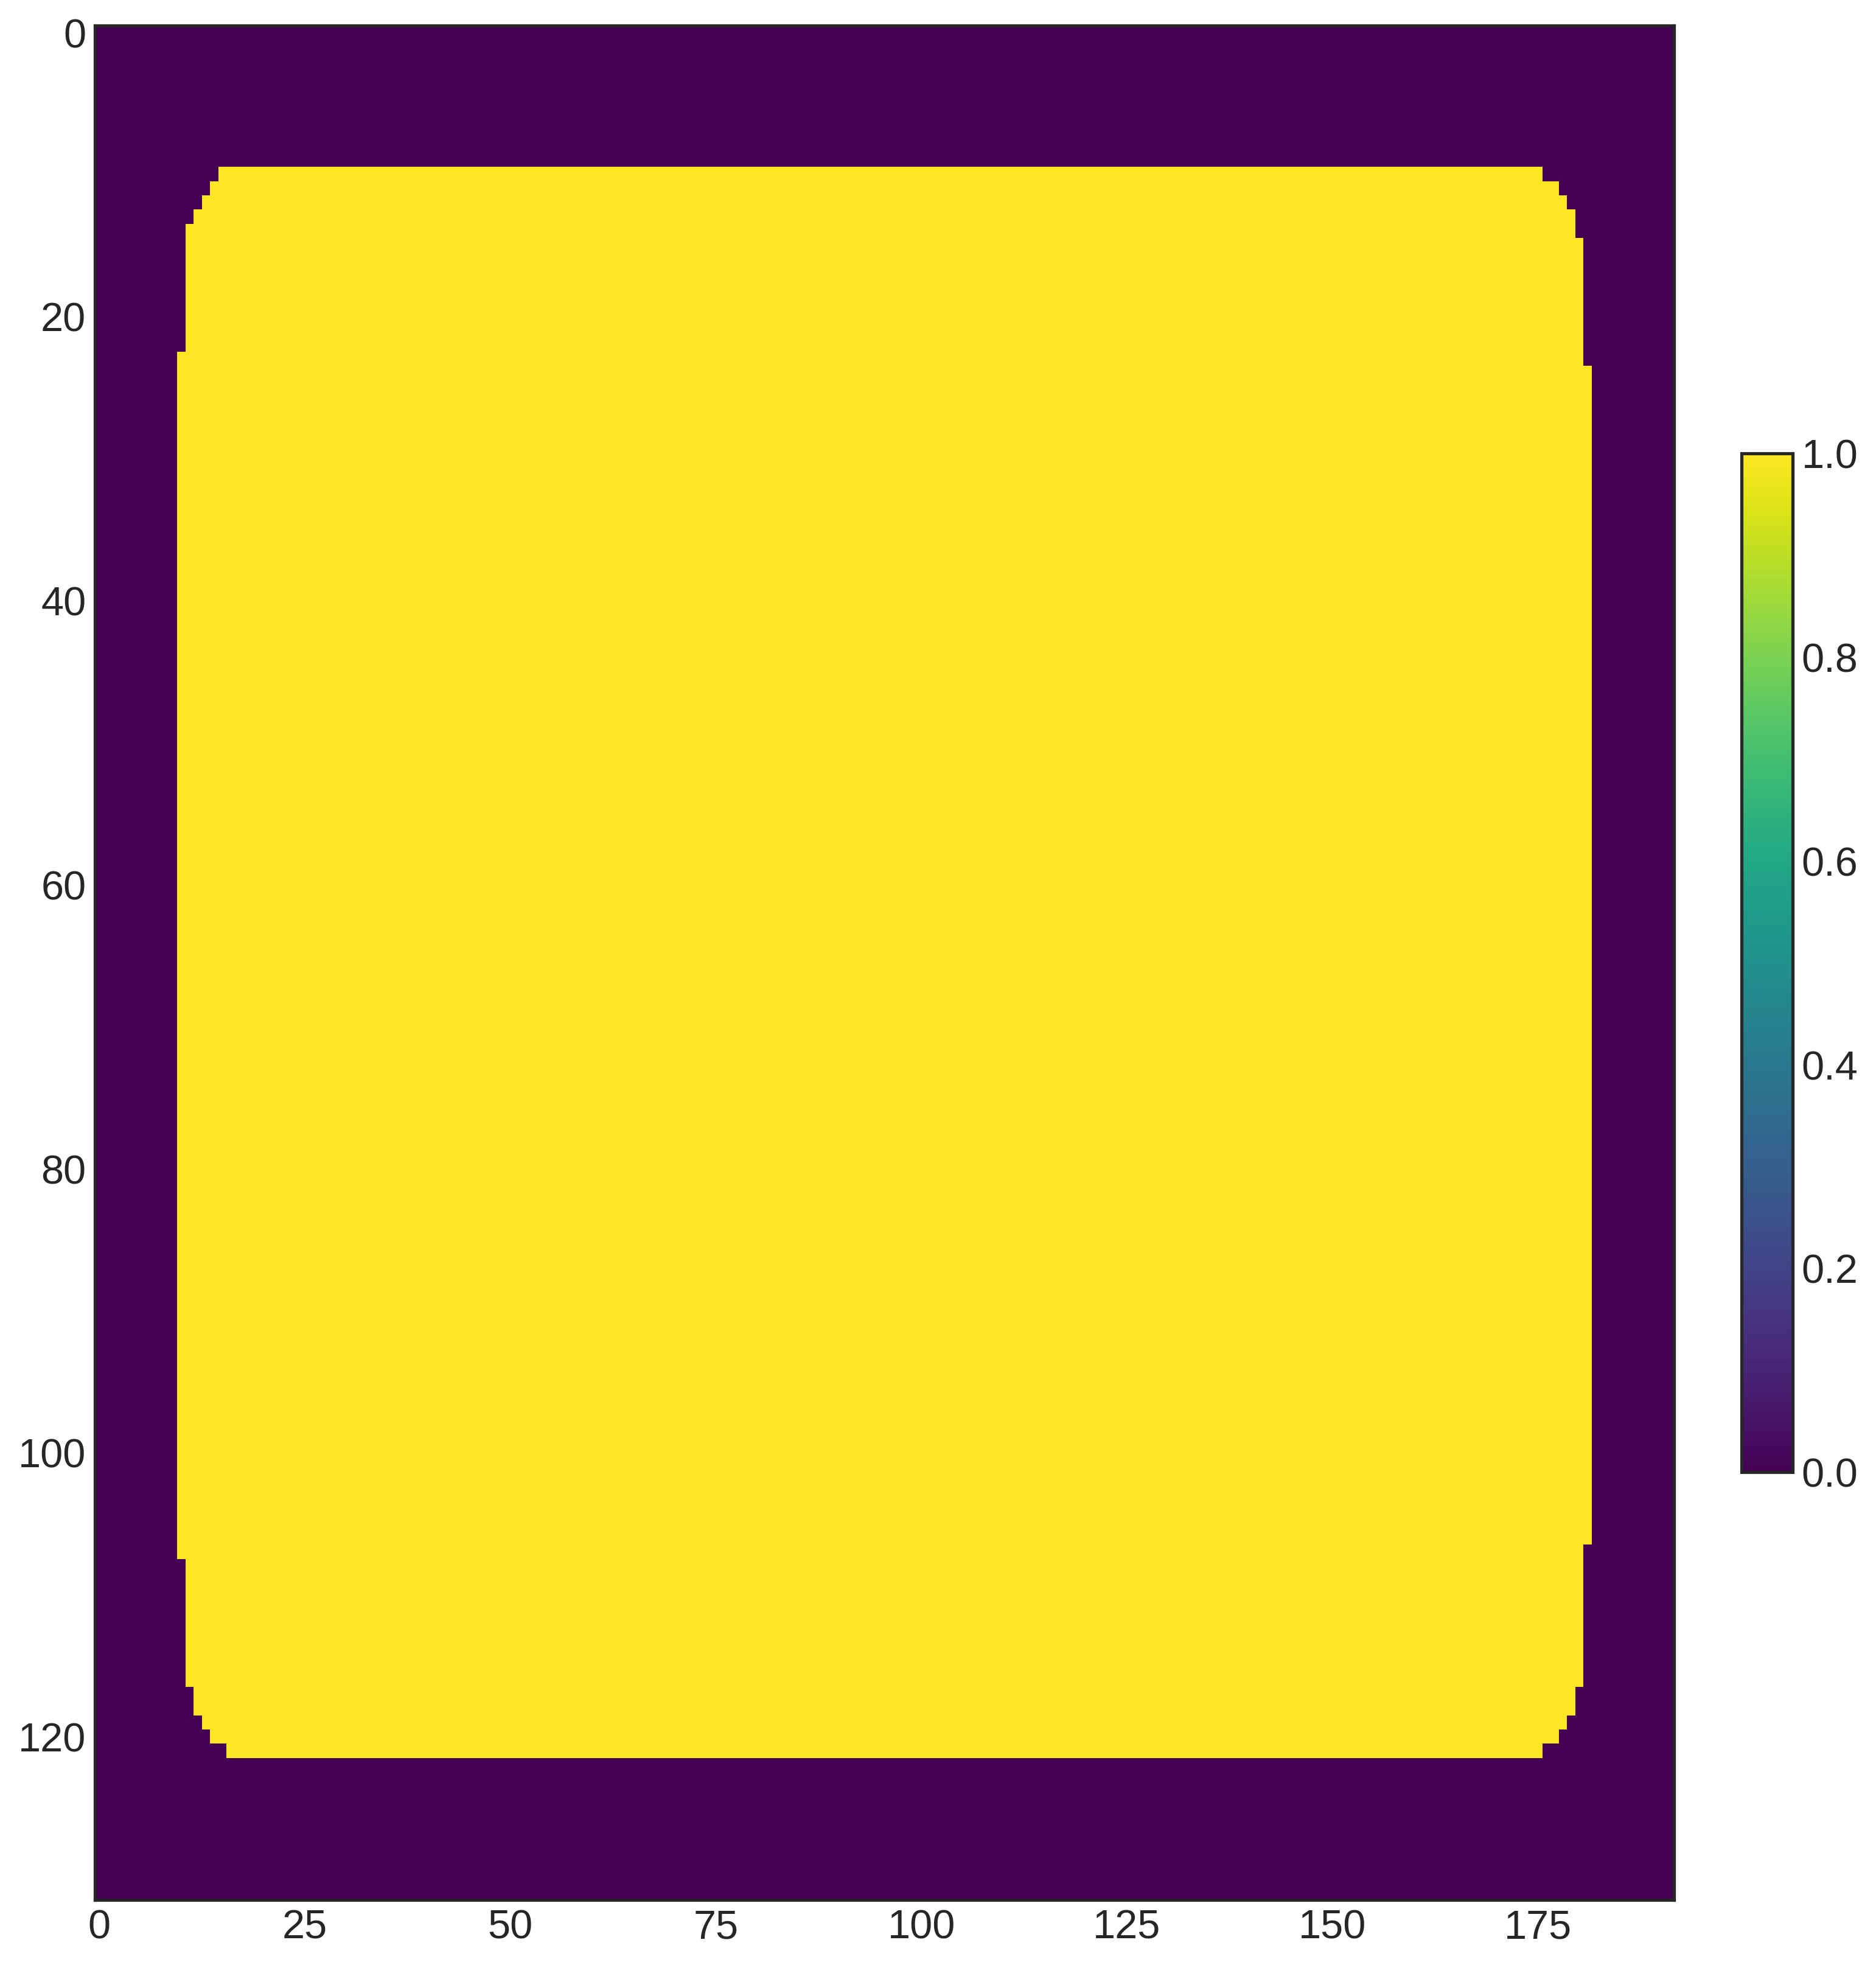

In [39]:
plt.figure(figsize=(12, 14))
plt.imshow(roi_mask[r1:r2, c1:c2], cmap="viridis", aspect=aspect)
plt.colorbar(fraction=0.03, pad=0.04)
plt.show()


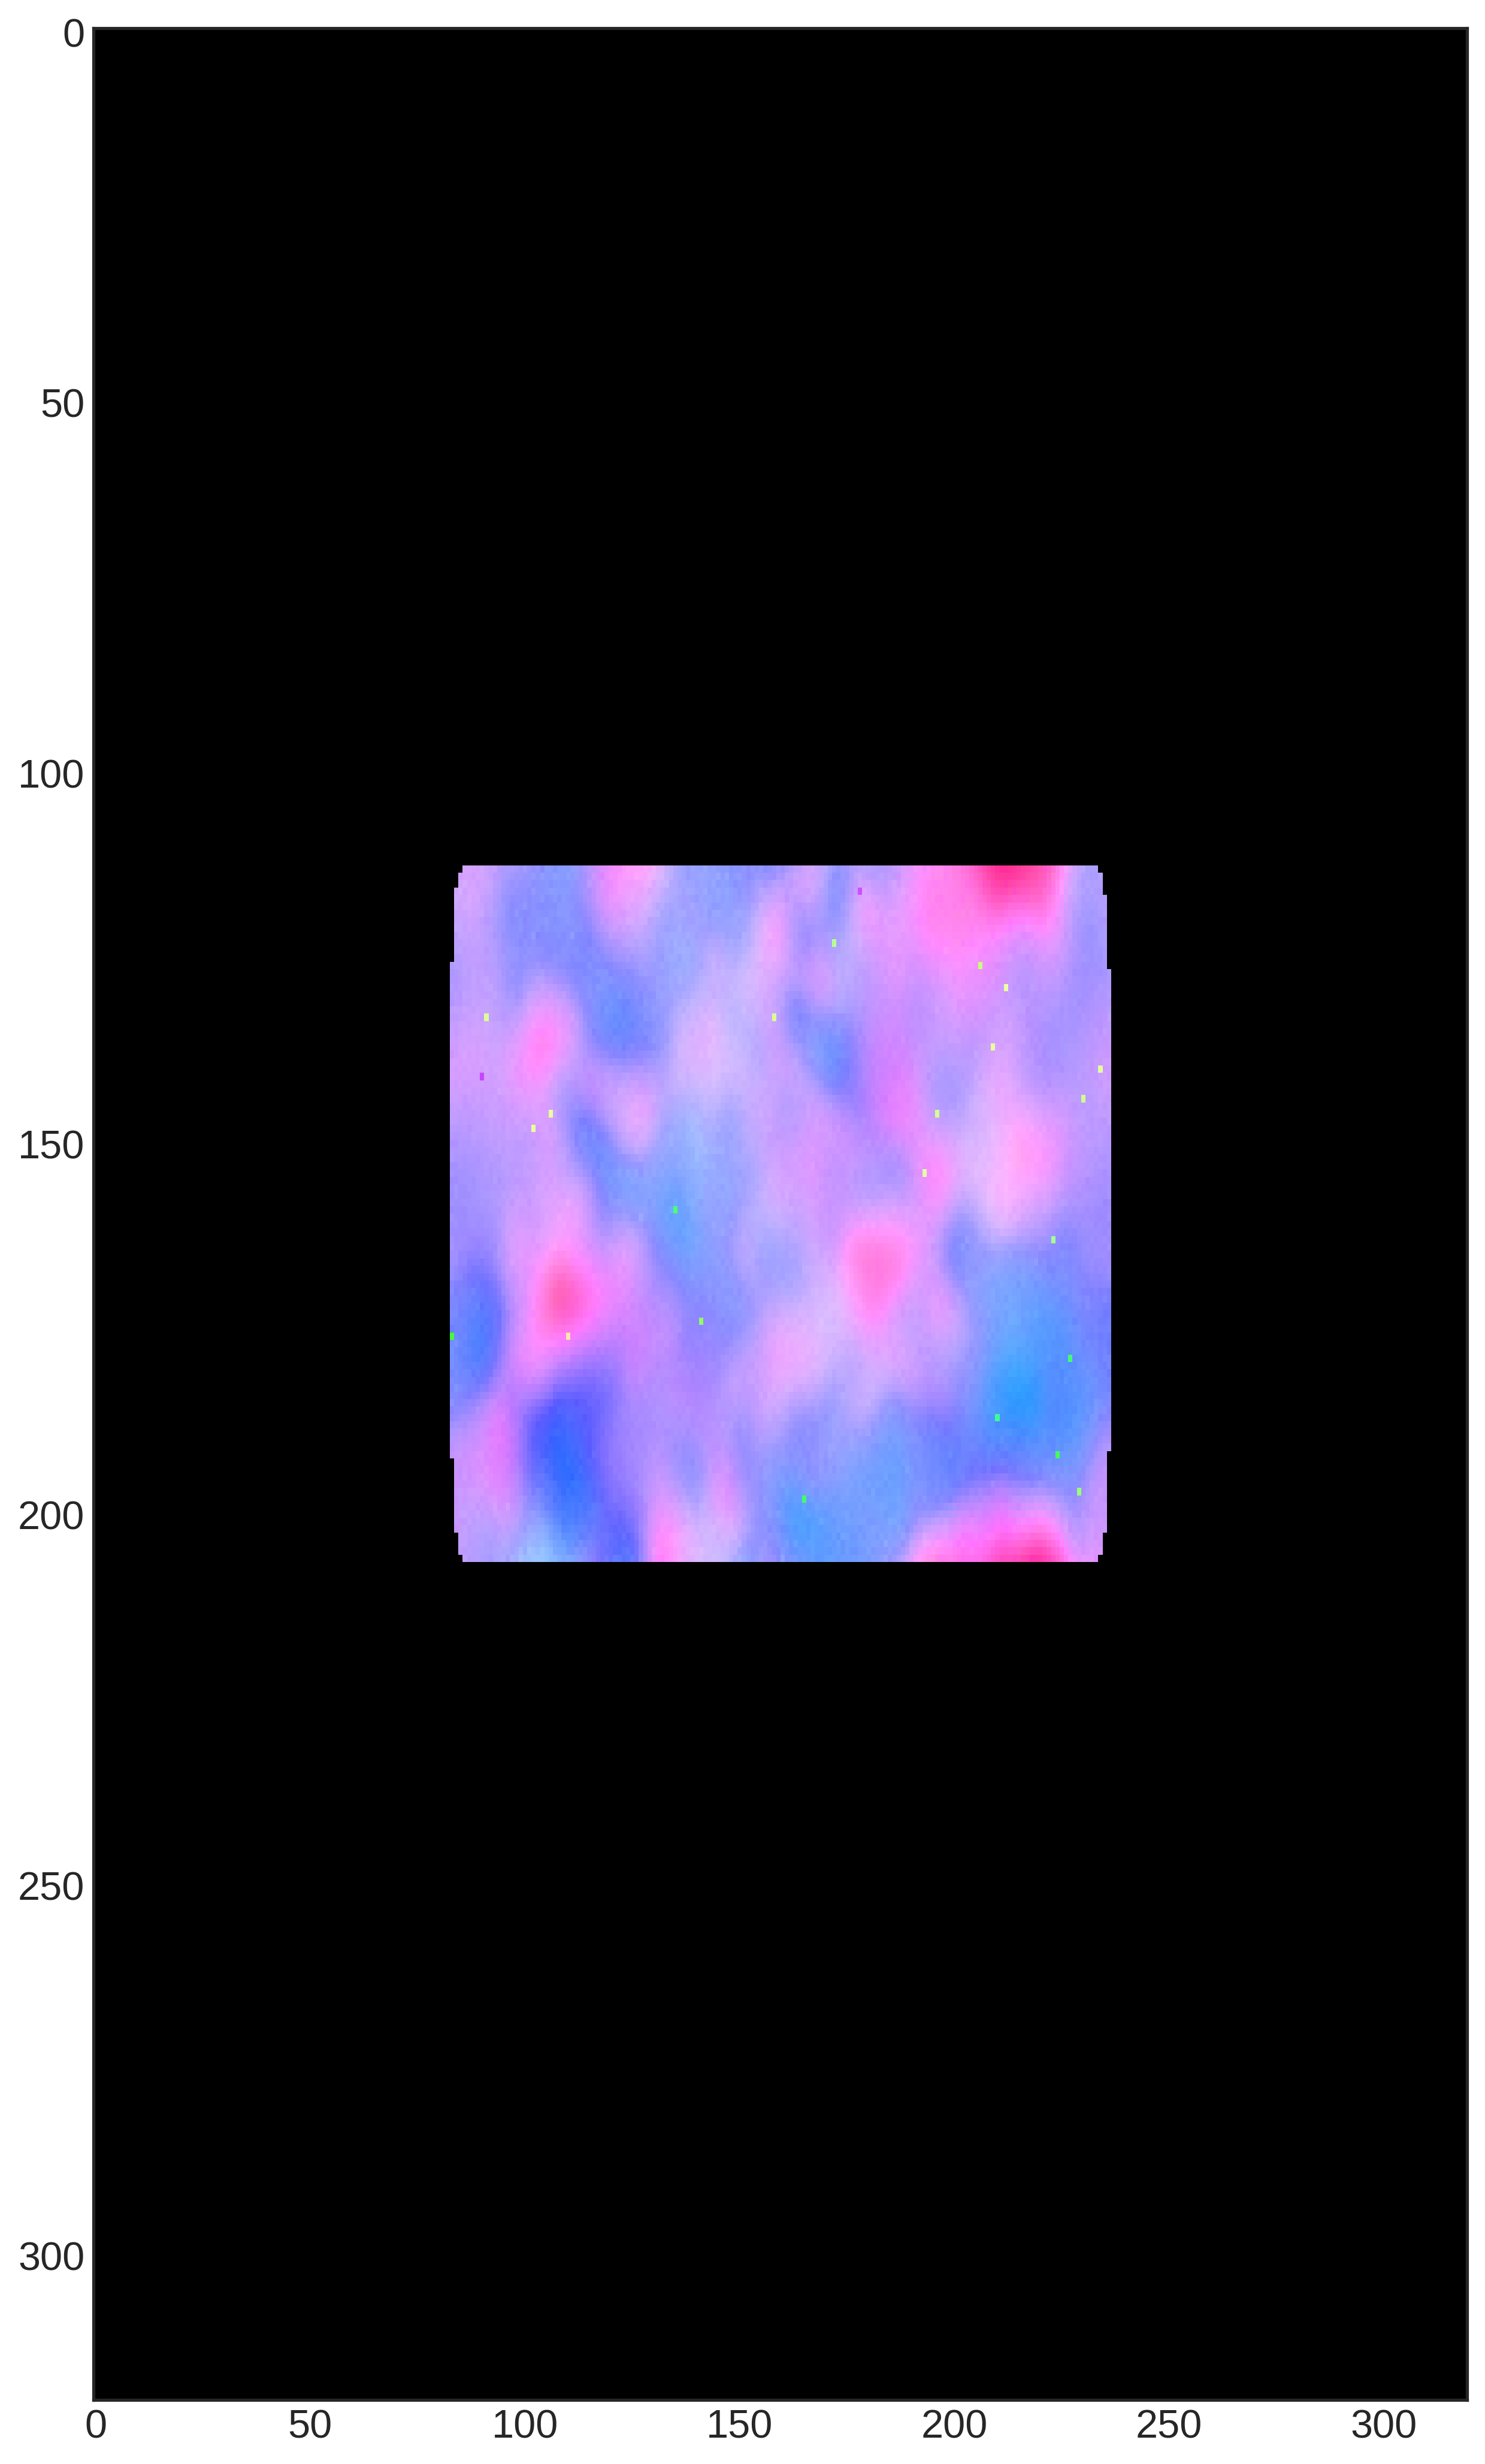

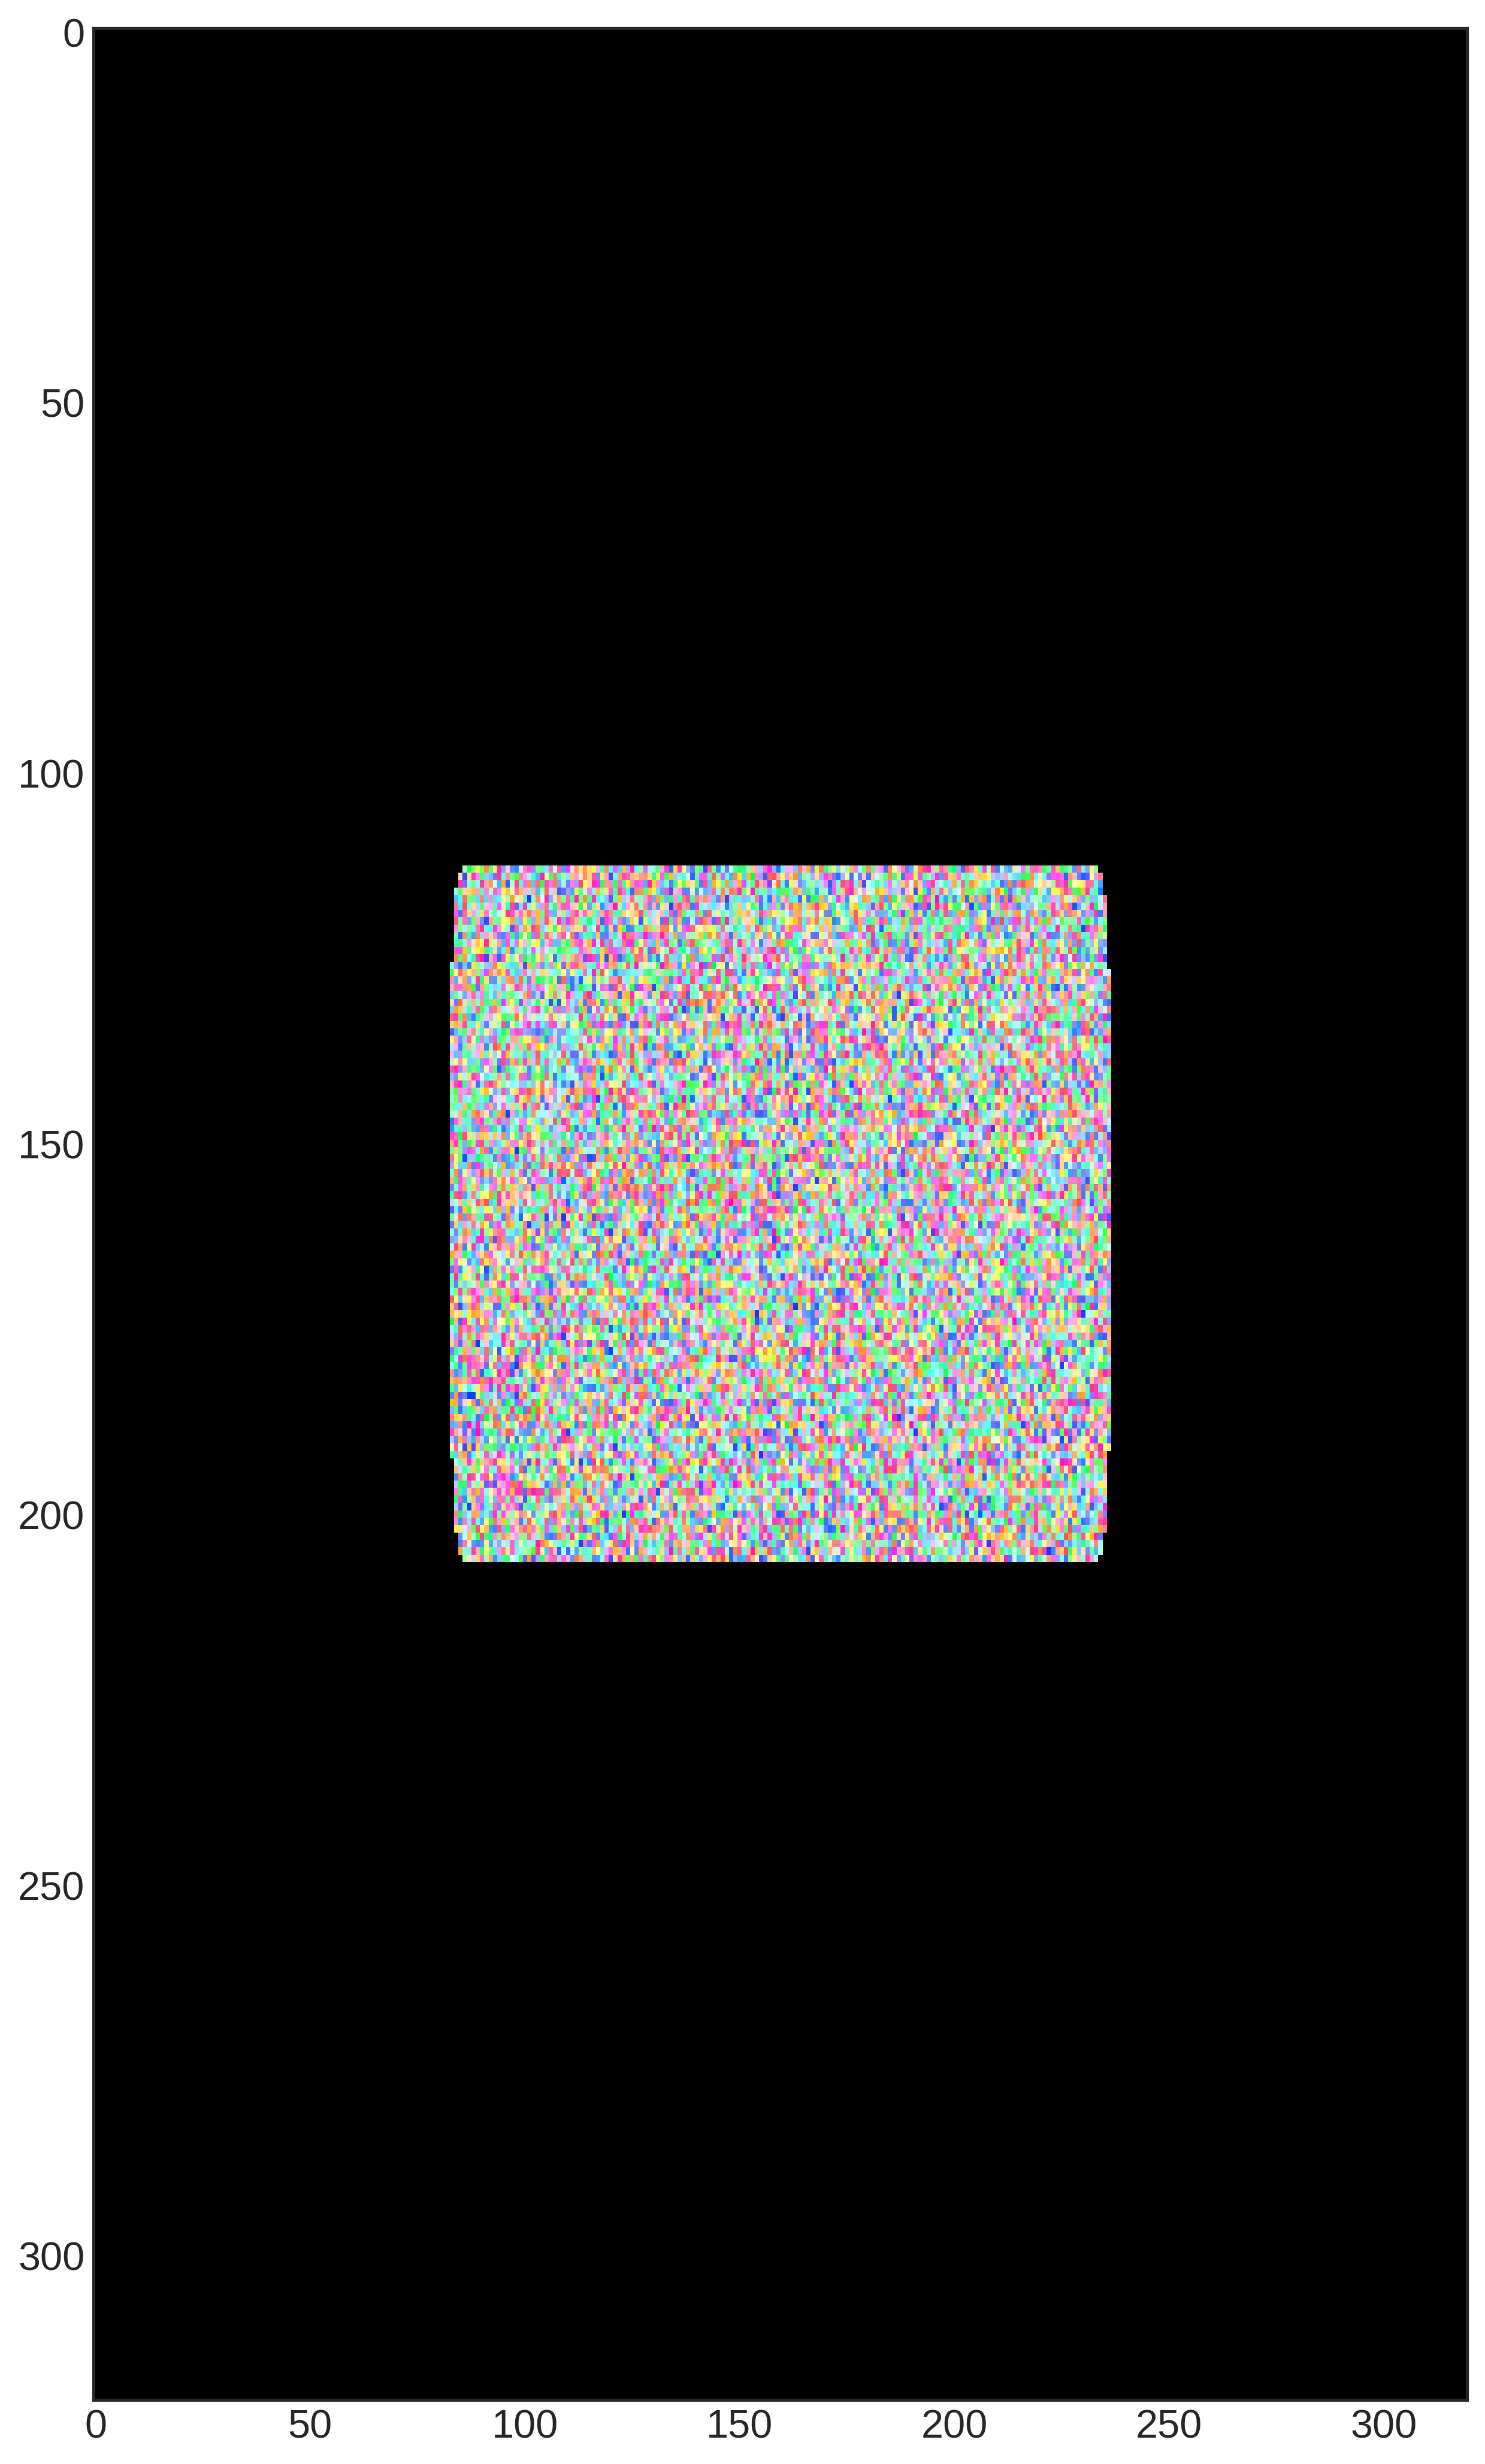

In [47]:
plt.figure(figsize=(12, 14))
plt.imshow(rgbmap1, aspect=aspect)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 14))
plt.imshow(rgbmap2, aspect=aspect)
plt.tight_layout()
plt.show()



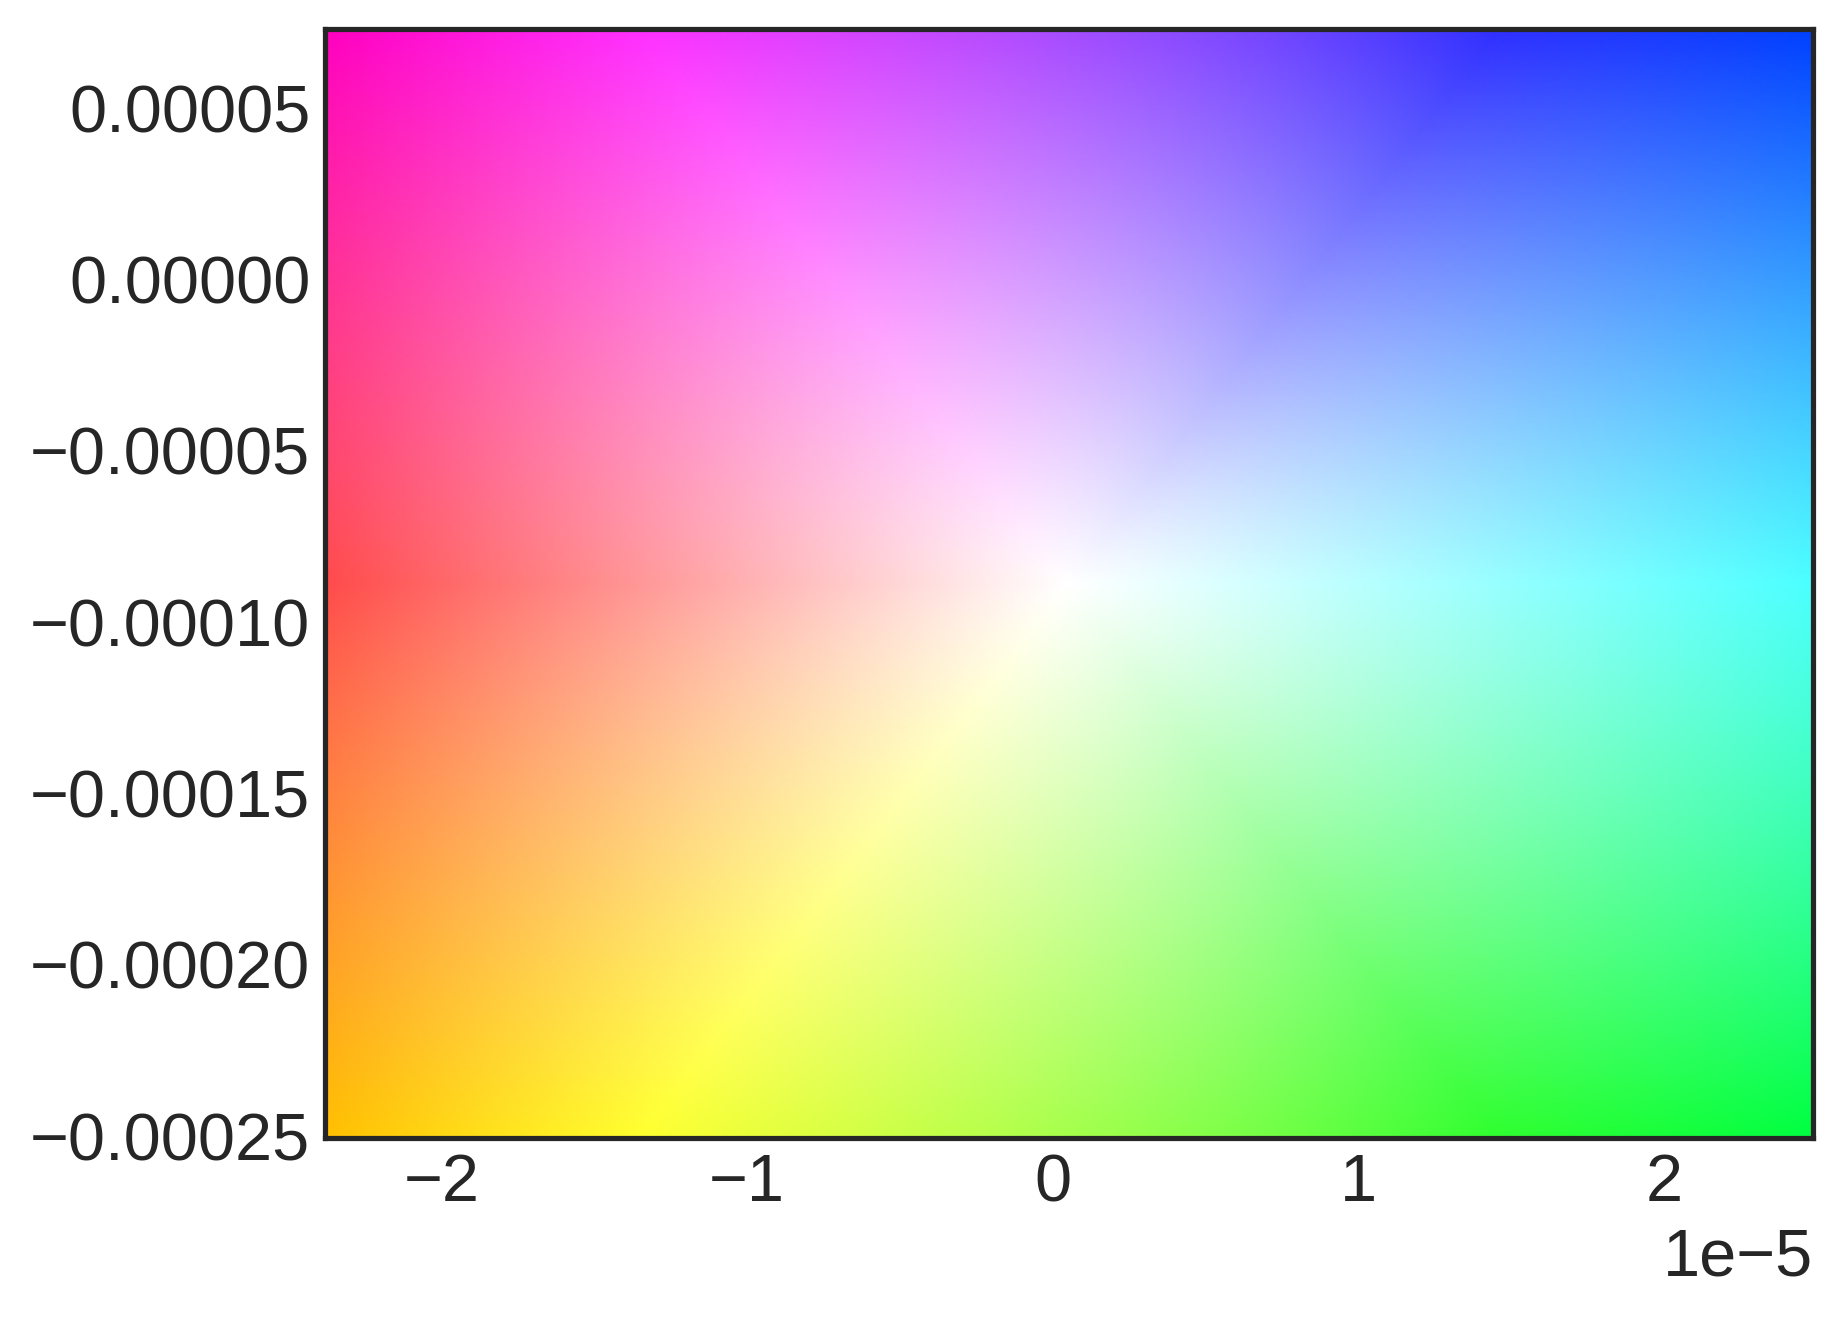

In [41]:
plt.pcolormesh(*colorgrid, colorkey, shading="auto")